In [55]:
import tensorflow as tf
from tensorflow.keras import Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt
import numpy as np

### 1. Load the MNIST dataset

The MNIST dataset consists of 60,000 training images and 10,000 test images of handwritten digits. Each image is 28x28 pixels.

Shape of x_train: (60000, 28, 28)
Shape of y_train: (60000,)
Shape of x_test: (10000, 28, 28)
Shape of y_test: (10000,)


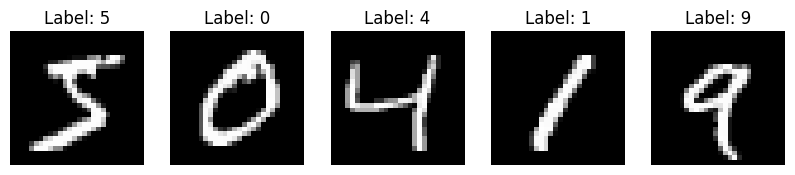

In [56]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print(f"Shape of x_train: {x_train.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of x_test: {x_test.shape}")
print(f"Shape of y_test: {y_test.shape}")

# Display the first few images
plt.figure(figsize=(10, 5))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.show()

### 2. Preprocess the data

We need to:
- Normalize the pixel values from [0, 255] to [0, 1].
- One-hot encode the labels (e.g., 5 becomes `[0,0,0,0,0,1,0,0,0,0]`).

In [57]:
# Normalize pixel values
x_train_normalized = x_train.astype('float32') / 255.0
x_test_normalized = x_test.astype('float32') / 255.0

# One-hot encode labels
num_classes = 10
y_train_one_hot = to_categorical(y_train, num_classes)
y_test_one_hot = to_categorical(y_test, num_classes)

print(f"Shape of x_train_normalized: {x_train_normalized.shape}")
print(f"Shape of y_train_one_hot: {y_train_one_hot.shape}")
print(y_train[10],y_train_one_hot[10])

Shape of x_train_normalized: (60000, 28, 28)
Shape of y_train_one_hot: (60000, 10)
3 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]


### 3. Build the Neural Network Model

We'll create a simple Sequential model with:
- `Flatten` layer to convert the 2D image (28x28) into a 1D array (784 pixels).
- Two `Dense` (fully connected) layers with `relu` activation.
- An output `Dense` layer with `softmax` activation for classification into 10 classes.

In [58]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(), # Input layer, flattens 28x28 images into a 784-element vector
    Dense(128, activation='relu'), # Hidden layer with 128 neurons and ReLU activation
    Dense(64, activation='relu'),  # Another hidden layer with 64 neurons and ReLU activation
    Dense(num_classes, activation='softmax') # Output layer with 10 neurons (for 10 digits) and softmax activation
])

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

### 4. Compile the Model

We need to specify:
- An `optimizer` (e.g., 'adam') to update the weights.
- A `loss` function (`categorical_crossentropy` for one-hot encoded labels).
- `metrics` to monitor during training (e.g., 'accuracy').

In [59]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

### 5. Train the Model

Now, let's train the model using the training data. We'll specify the number of `epochs` (how many times to iterate over the entire dataset) and `batch_size`.

In [60]:
history = model.fit(x_train_normalized, y_train_one_hot,
                    epochs=10,
                    batch_size=32,
                    validation_split=0.2) # Use 20% of training data for validation

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8619 - loss: 0.4776 - val_accuracy: 0.9615 - val_loss: 0.1307
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9659 - loss: 0.1142 - val_accuracy: 0.9678 - val_loss: 0.1084
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9771 - loss: 0.0748 - val_accuracy: 0.9703 - val_loss: 0.0996
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9841 - loss: 0.0501 - val_accuracy: 0.9663 - val_loss: 0.1178
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9858 - loss: 0.0424 - val_accuracy: 0.9753 - val_loss: 0.0944
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9897 - loss: 0.0302 - val_accuracy: 0.9707 - val_loss: 0.1116
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9919 - loss: 0.0254 - val_accuracy: 0.9762 - val_loss: 0.0949
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9936 - loss: 0.0186 -

### 6. Evaluate the Model

After training, we evaluate the model's performance on the unseen test data.

In [61]:
loss, accuracy = model.evaluate(x_test_normalized, y_test_one_hot, verbose=0)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

Test Loss: 0.0986
Test Accuracy: 0.9764


### 7. Visualize Training History

It's good practice to visualize the training and validation accuracy/loss over epochs to check for overfitting or underfitting.

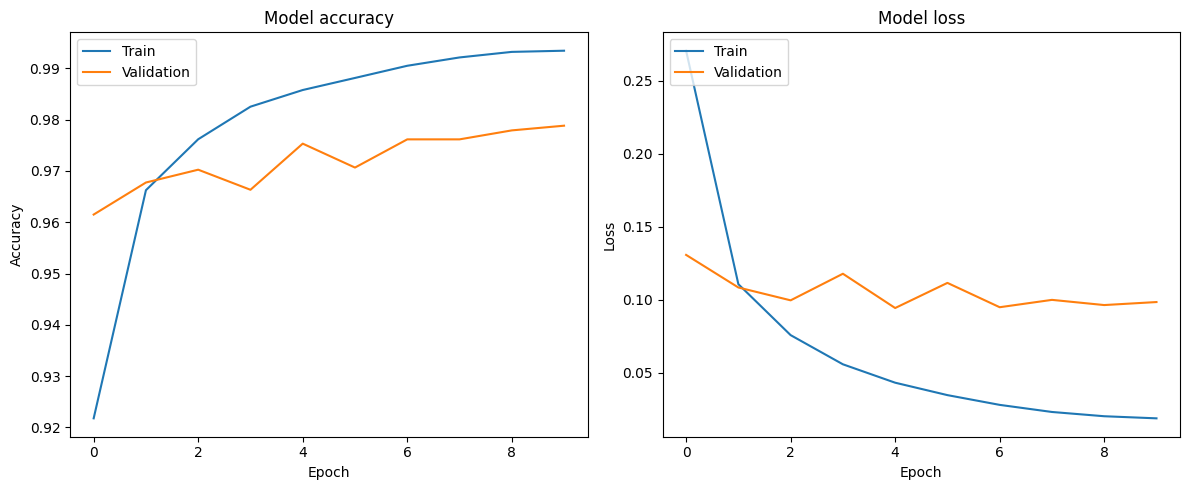

In [62]:
plt.figure(figsize=(12, 5))

# Plot training & validation accuracy values
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.tight_layout()
plt.show()

### 8. Make Predictions (Optional)

Let's see how the model predicts on a few test images.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


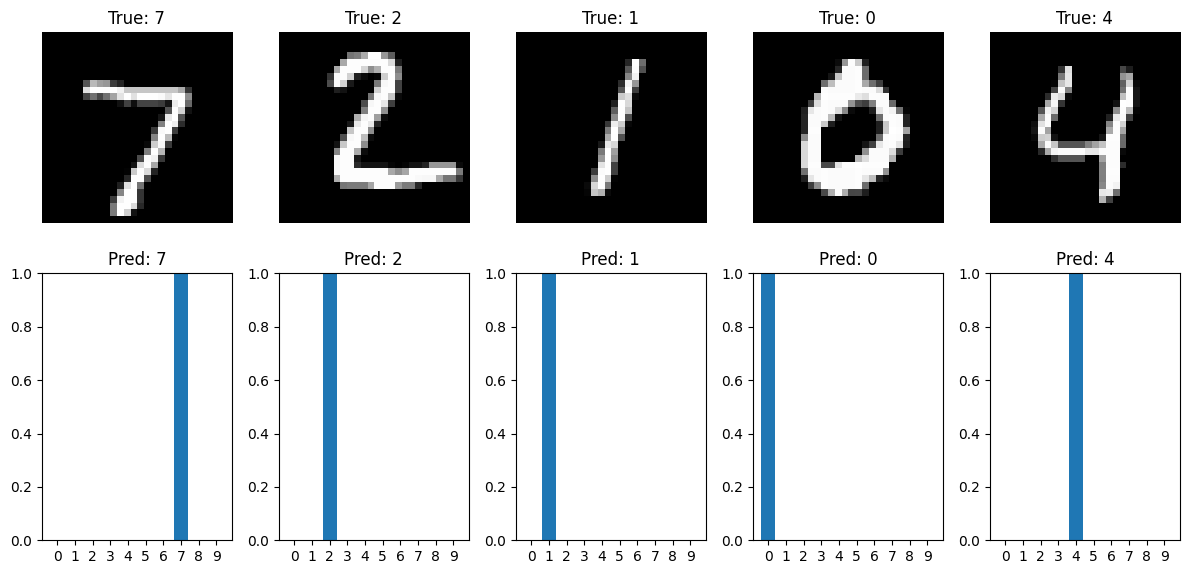

In [63]:
predictions = model.predict(x_test_normalized)

plt.figure(figsize=(12, 6))
for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"True: {y_test[i]}")
    plt.axis('off')

    predicted_label = np.argmax(predictions[i])
    plt.subplot(2, 5, i + 6)
    plt.bar(range(num_classes), predictions[i])
    plt.xticks(range(num_classes))
    plt.title(f"Pred: {predicted_label}")
    plt.ylim(0, 1)

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step
Predicted digit for 3_100.png: 3


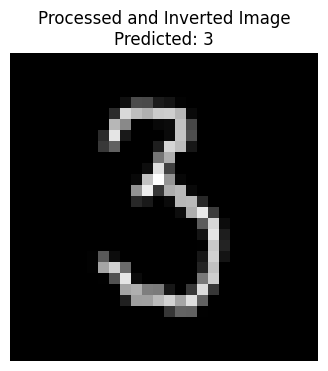

In [66]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

image_path = '3_100.png'
try:
    img = Image.open(image_path).convert('L') # Convert to grayscale

    # Resize the image to 28x28 pixels
    img = img.resize((28, 28))

    # Convert image to numpy array and normalize
    img_array = np.array(img)
    img_array = img_array.astype('float32') / 255.0

    # Invert colors: black becomes white, white becomes black
    img_array = 1.0 - img_array

    # The model expects a batch of images, so add an extra dimension
    # Reshape from (28, 28) to (1, 28, 28)
    img_array = np.expand_dims(img_array, axis=0)

    # Make a prediction (assuming 'model' and 'num_classes' are defined)
    prediction = model.predict(img_array)
    predicted_label = np.argmax(prediction[0])

    print(f"Predicted digit for {image_path}: {predicted_label}")

    # Display the processed image
    plt.figure(figsize=(4, 4))
    plt.imshow(img_array.squeeze(), cmap='gray')
    plt.title(f"Processed and Inverted Image\nPredicted: {predicted_label}")
    plt.axis('off')
    plt.show()

except FileNotFoundError:
    print(f"Error: The file '{image_path}' was not found. Please upload it to your Colab environment.")
except Exception as e:
    print(f"An error occurred: {e}")